# Week 3 · Visualization & Interpretation
**Kagnus Data Analytics Internship · Food Delivery Operations**

**Goal:** turn the Week 2 findings into five clear charts, export each as a PNG, and interpret every chart in 2 to 3 sentences (what it shows, what it may indicate, and one limitation).

**The five charts**
1. Delivery-duration distribution (histogram)
2. Median delivery duration by traffic level (bar chart)
3. Average delivery duration by weather condition (bar chart)
4. Delivery distance vs. delivery duration (scatter plot)
5. Delivery-duration distribution by vehicle type (box plot)

**How to read this notebook:** every value plotted and quoted in the interpretations is calculated by code from the cleaned dataset, and a small table of those values sits above each chart. Interpretations describe **associations**, not causes. Bar charts start at zero so the bar heights are not misleading.

## 1. Setup and Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", font_scale=1.05)

def md_table(frame):
    # Turn a DataFrame into a Markdown table so results render cleanly on GitHub
    cols = [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(cols) + " |", "| " + " | ".join(["---"] * len(cols)) + " |"]
    for _, row in frame.astype(object).iterrows():
        lines.append("| " + " | ".join(str(v) for v in row.values) + " |")
    return "\n".join(lines)

def show_md(*lines):
    display(Markdown("\n".join(lines)))

### 1.1 Load the cleaned dataset and derive distance

**What:** load the Week 1 cleaned file, keep valid delivery durations, and recalculate the straight-line distance used in Week 2 (valid coordinates only).
**Why:** all five charts must come from the same cleaned data and the same distance definition as Week 2, so the results stay consistent.

In [2]:
CWD = os.getcwd()
PROJECT_ROOT = os.path.dirname(CWD) if os.path.basename(CWD).lower() == "notebooks" else CWD

CLEAN_NAME = "cleaned_food_delivery.csv"
candidates = [os.path.join(PROJECT_ROOT, "data", "processed", CLEAN_NAME), os.path.join(CWD, CLEAN_NAME)]
CLEAN_PATH = next((p for p in candidates if os.path.exists(p)), None)
if CLEAN_PATH is None:
    raise FileNotFoundError("Cleaned CSV not found. Run the Week 1 notebook first. Looked in:\n  " + "\n  ".join(candidates))

df = pd.read_csv(CLEAN_PATH)
TARGET = "Time_taken_min"                      # delivery duration in minutes
assert TARGET in df.columns, f"'{TARGET}' not found. Columns: {list(df.columns)}"

n_all = len(df)
df = df[df[TARGET].notna() & (df[TARGET] > 0)].copy()      # valid durations only
print(f"Loaded {n_all:,} rows; {len(df):,} have a valid delivery duration.")

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

coord_cols = ["Restaurant_latitude", "Restaurant_longitude", "Delivery_location_latitude", "Delivery_location_longitude"]
HAS_DISTANCE = all(c in df.columns for c in coord_cols)
if HAS_DISTANCE:
    valid = df["has_valid_coordinates"].astype(bool) if "has_valid_coordinates" in df.columns else (
        df["Restaurant_latitude"].between(6, 38) & df["Restaurant_longitude"].between(68, 98)
        & df["Delivery_location_latitude"].between(6, 38) & df["Delivery_location_longitude"].between(68, 98))
    df["distance_km"] = haversine_km(df["Restaurant_latitude"], df["Restaurant_longitude"],
                                     df["Delivery_location_latitude"], df["Delivery_location_longitude"]).where(valid)
    print(f"Distance available for {int(df['distance_km'].notna().sum()):,} deliveries.")

Loaded 45,584 rows; 45,584 have a valid delivery duration.
Distance available for 41,513 deliveries.


In [3]:
# Where the charts are saved
VIS_DIR = os.path.join(PROJECT_ROOT, "visualizations")
os.makedirs(VIS_DIR, exist_ok=True)
exported = []

def save_chart(fig, filename):
    # Save the exact figure that is displayed, so the PNG matches the notebook
    path = os.path.join(VIS_DIR, filename)
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    exported.append(path)
    print("Saved:", path)

MIN_N = 30   # groups smaller than this are called out as small

## 2. Chart 1: Delivery-Duration Distribution (Histogram)

**What:** a histogram of delivery duration in 2-minute bins, with the mean, median and middle 50% marked.
**Why:** it shows what a normal delivery looks like, how spread out the times are, and whether extreme values exist. This is the baseline for every other chart.

In [4]:
d = df[TARGET]
q1, q3 = d.quantile(0.25), d.quantile(0.75)
iqr = q3 - q1
skew = d.skew()
n_extreme = int(((d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)).sum())

edges = np.arange(int(d.min()), int(d.max()) + 3, 2)        # 2-minute bins
counts, edges = np.histogram(d, bins=edges)
peak = counts.argmax()
peak_lo, peak_hi = edges[peak], edges[peak + 1]

values1 = pd.DataFrame({
    "Statistic": ["Deliveries", "Mean (min)", "Median (min)", "25th percentile (min)", "75th percentile (min)",
                  "Minimum / maximum (min)", "Skewness", "Tallest 2-min bin", "Outliers (1.5 x IQR rule)"],
    "Value": [f"{len(d):,}", round(d.mean(), 1), round(d.median(), 1), round(q1, 1), round(q3, 1),
              f"{d.min()} / {d.max()}", round(skew, 2), f"{peak_lo} to {peak_hi} min ({counts.max():,} deliveries)", f"{n_extreme:,}"],
})
show_md("**Values used in Chart 1**", "", md_table(values1))

**Values used in Chart 1**

| Statistic | Value |
| --- | --- |
| Deliveries | 45,584 |
| Mean (min) | 26.3 |
| Median (min) | 26.0 |
| 25th percentile (min) | 19.0 |
| 75th percentile (min) | 32.0 |
| Minimum / maximum (min) | 10 / 54 |
| Skewness | 0.49 |
| Tallest 2-min bin | 26 to 28 min (4,097 deliveries) |
| Outliers (1.5 x IQR rule) | 270 |

Saved: C:\Users\HP\Documents\food-delivery-data-analysis\visualizations\01_delivery_duration_distribution.png


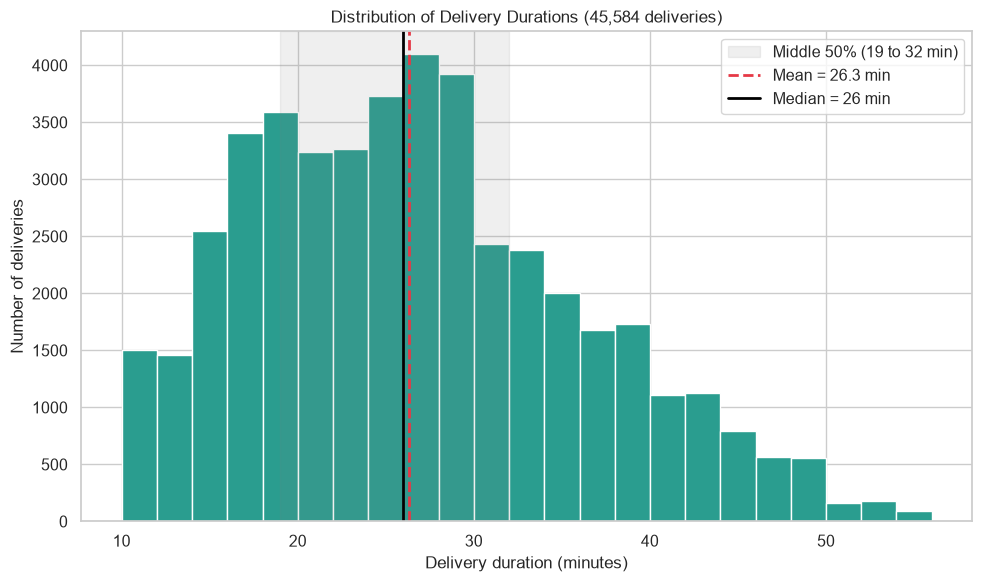

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(d, bins=edges, color="#2a9d8f", edgecolor="white")
ax.axvspan(q1, q3, color="grey", alpha=0.12, label=f"Middle 50% ({q1:.0f} to {q3:.0f} min)")
ax.axvline(d.mean(), color="#e63946", linestyle="--", linewidth=2, label=f"Mean = {d.mean():.1f} min")
ax.axvline(d.median(), color="black", linestyle="-", linewidth=2, label=f"Median = {d.median():.0f} min")
ax.set_title(f"Distribution of Delivery Durations ({len(d):,} deliveries)")
ax.set_xlabel("Delivery duration (minutes)")
ax.set_ylabel("Number of deliveries")
ax.legend()
fig.tight_layout()
save_chart(fig, "01_delivery_duration_distribution.png")
plt.show()

In [6]:
if skew > 0.5:
    shape = "right-skewed"
elif skew < -0.5:
    shape = "left-skewed"
else:
    shape = "roughly symmetric"

show_md("**Interpretation:** " +
    f"Most deliveries are concentrated between {q1:.0f} and {q3:.0f} minutes (the middle 50%), with the tallest bar at {peak_lo} to {peak_hi} minutes ({counts.max():,} deliveries), and the shape is {shape} (skewness {skew:.2f}). "
    f"This suggests a typical delivery of about {d.median():.0f} minutes, with {n_extreme:,} deliveries ({n_extreme / len(d) * 100:.1f}%) flagged as extreme by the 1.5 x IQR rule and the slowest taking {d.max()} minutes. "
    "A limitation is that the chart pools every condition together, so it cannot show why some deliveries were slower, and its look depends on the 2-minute bin width.")

**Interpretation:** Most deliveries are concentrated between 19 and 32 minutes (the middle 50%), with the tallest bar at 26 to 28 minutes (4,097 deliveries), and the shape is roughly symmetric (skewness 0.49). This suggests a typical delivery of about 26 minutes, with 270 deliveries (0.6%) flagged as extreme by the 1.5 x IQR rule and the slowest taking 54 minutes. A limitation is that the chart pools every condition together, so it cannot show why some deliveries were slower, and its look depends on the 2-minute bin width.

## 3. Chart 2: Median Delivery Duration by Traffic Level (Bar Chart)

**What:** a bar chart of the **median** duration for each traffic category, with each group's size shown.
**Why:** traffic is a key operational factor. The median is used because it is less affected by a few very slow deliveries, and group sizes show how much data sits behind each bar.

In [7]:
TRAFFIC_COL = "Road_traffic_density"
traffic_ok = TRAFFIC_COL in df.columns
if traffic_ok:
    sub = df.dropna(subset=[TRAFFIC_COL])
    traffic_excl = len(df) - len(sub)
    g = sub.groupby(TRAFFIC_COL).agg(n=(TARGET, "count"), median=(TARGET, "median"), mean=(TARGET, "mean"),
                                     mean_dist=("distance_km", "mean") if HAS_DISTANCE else (TARGET, "mean"))
    order = ["Low", "Medium", "High", "Jam"]
    g = g.reindex([c for c in order if c in g.index]) if set(g.index) <= set(order) else g.sort_values("median")
    values2 = g.reset_index().rename(columns={TRAFFIC_COL: "Traffic category", "n": "Deliveries", "median": "Median (min)",
                                              "mean": "Mean (min)", "mean_dist": "Mean distance (km)"}).round(1)
    values2["Deliveries"] = values2["Deliveries"].astype(int)
    show_md("**Values used in Chart 2**", "", md_table(values2))
    print(f"Deliveries excluded (traffic value missing): {traffic_excl:,}")
else:
    show_md("The traffic field is not available, so Chart 2 could not be created.")

**Values used in Chart 2**

| Traffic category | Deliveries | Median (min) | Mean (min) | Mean distance (km) |
| --- | --- | --- | --- | --- |
| Low | 15476 | 20.0 | 21.3 | 8.1 |
| Medium | 10945 | 27.0 | 26.7 | 11.1 |
| High | 4423 | 27.0 | 27.2 | 4.4 |
| Jam | 14139 | 31.0 | 31.2 | 12.0 |

Deliveries excluded (traffic value missing): 601


Saved: C:\Users\HP\Documents\food-delivery-data-analysis\visualizations\02_traffic_comparison.png


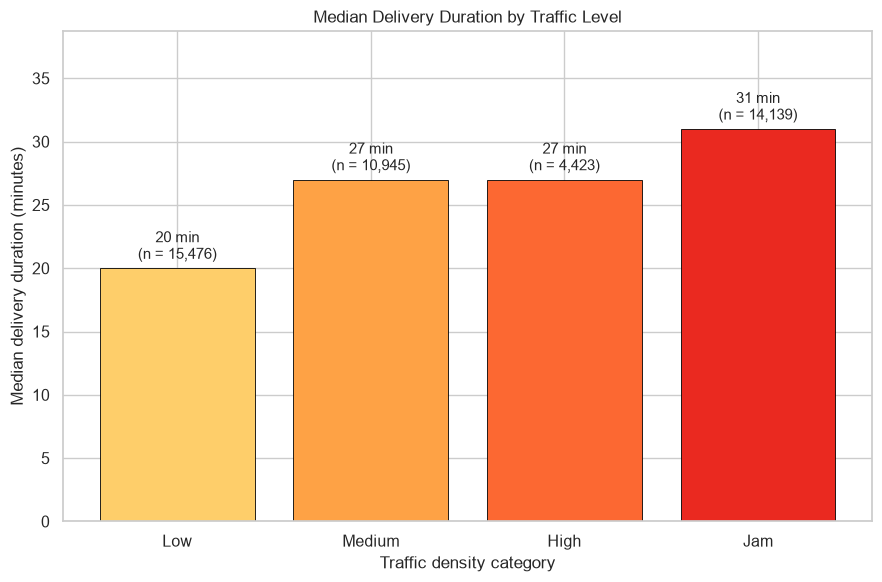

In [8]:
if traffic_ok:
    fig, ax = plt.subplots(figsize=(9, 6))
    palette = sns.color_palette("YlOrRd", n_colors=len(g) + 2)[1:-1]
    bars = ax.bar(g.index, g["median"], color=palette, edgecolor="black", linewidth=0.6)
    for bar, med, n in zip(bars, g["median"], g["n"]):
        ax.text(bar.get_x() + bar.get_width() / 2, med + 0.4, f"{med:.0f} min\n(n = {int(n):,})", ha="center", va="bottom", fontsize=11)
    ax.set_ylim(0, g["median"].max() * 1.25)          # axis starts at zero so bar heights are not misleading
    ax.set_title("Median Delivery Duration by Traffic Level")
    ax.set_xlabel("Traffic density category")
    ax.set_ylabel("Median delivery duration (minutes)")
    fig.tight_layout()
    save_chart(fig, "02_traffic_comparison.png")
    plt.show()

In [9]:
if traffic_ok:
    hi, lo = g["median"].idxmax(), g["median"].idxmin()
    steady = bool(np.all(np.diff(g["median"].values) >= 0)) if set(g.index) <= set(order) else False
    pattern = ("The median rises steadily across the categories in the order shown, " if steady
               else "The medians do not rise strictly in the order shown, ")
    show_md("**Interpretation:** " +
        f"Median delivery duration is highest in `{hi}` traffic ({g.loc[hi, 'median']:.0f} min, n = {int(g.loc[hi, 'n']):,}) and lowest in `{lo}` ({g.loc[lo, 'median']:.0f} min, n = {int(g.loc[lo, 'n']):,}), a gap of {g.loc[hi, 'median'] - g.loc[lo, 'median']:.0f} minutes. "
        f"{pattern}which indicates an association between traffic level and delivery time, not proof that traffic caused it. "
        + (f"A limitation is that `{hi}` deliveries also average {g.loc[hi, 'mean_dist']:.1f} km versus {g.loc[lo, 'mean_dist']:.1f} km for `{lo}`, so distance may explain part of the gap, and medians hide the spread within each category ({traffic_excl:,} deliveries with missing traffic are excluded)."
           if HAS_DISTANCE else f"A limitation is that medians hide the spread within each category, and {traffic_excl:,} deliveries with missing traffic are excluded."))

**Interpretation:** Median delivery duration is highest in `Jam` traffic (31 min, n = 14,139) and lowest in `Low` (20 min, n = 15,476), a gap of 11 minutes. The median rises steadily across the categories in the order shown, which indicates an association between traffic level and delivery time, not proof that traffic caused it. A limitation is that `Jam` deliveries also average 12.0 km versus 8.1 km for `Low`, so distance may explain part of the gap, and medians hide the spread within each category (601 deliveries with missing traffic are excluded).

## 4. Chart 3: Average Delivery Duration by Weather (Bar Chart)

**What:** a bar chart of the **average (mean)** duration for each weather category, with the overall mean as a reference line.
**Why:** the brief asks for averages here. The reference line shows which weather categories sit above or below the overall average.

In [10]:
WEATHER_COL = "Weather_conditions"
weather_ok = WEATHER_COL in df.columns
if weather_ok:
    sub = df.dropna(subset=[WEATHER_COL])
    weather_excl = len(df) - len(sub)
    w = sub.groupby(WEATHER_COL).agg(n=(TARGET, "count"), mean=(TARGET, "mean"), median=(TARGET, "median")).sort_values("mean", ascending=False)
    overall_mean = df[TARGET].mean()
    values3 = w.reset_index().rename(columns={WEATHER_COL: "Weather category", "n": "Deliveries", "mean": "Mean (min)", "median": "Median (min)"}).round(1)
    values3["Deliveries"] = values3["Deliveries"].astype(int)
    show_md("**Values used in Chart 3**", "", md_table(values3))
    print(f"Overall mean: {overall_mean:.2f} min | deliveries excluded (weather value missing): {weather_excl:,}")
else:
    show_md("The weather field is not available, so Chart 3 could not be created.")

**Values used in Chart 3**

| Weather category | Deliveries | Mean (min) | Median (min) |
| --- | --- | --- | --- |
| Cloudy | 7533 | 28.9 | 28.0 |
| Fog | 7653 | 28.9 | 28.0 |
| Windy | 7422 | 26.1 | 26.0 |
| Sandstorms | 7494 | 25.9 | 26.0 |
| Stormy | 7584 | 25.9 | 26.0 |
| Sunny | 7282 | 21.9 | 20.0 |

Overall mean: 26.29 min | deliveries excluded (weather value missing): 616


Saved: C:\Users\HP\Documents\food-delivery-data-analysis\visualizations\03_weather_comparison.png


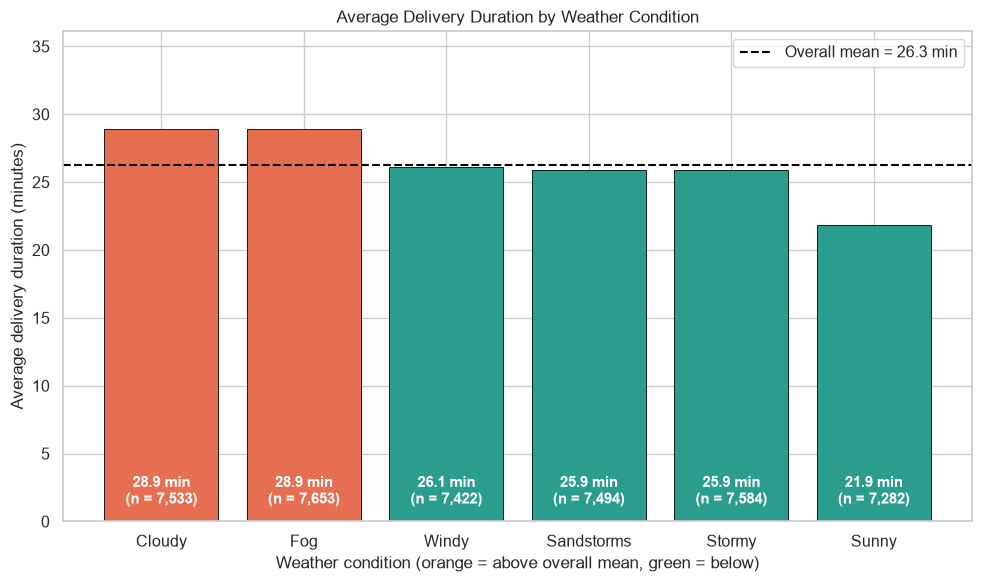

In [11]:
if weather_ok:
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = ["#e76f51" if m > overall_mean else "#2a9d8f" for m in w["mean"]]
    bars = ax.bar(w.index, w["mean"], color=colors, edgecolor="black", linewidth=0.6)
    ax.axhline(overall_mean, color="black", linestyle="--", linewidth=1.5, label=f"Overall mean = {overall_mean:.1f} min")
    for bar, m, n in zip(bars, w["mean"], w["n"]):
        # Labels sit inside the bars (near the base) so they never collide with the mean line
        ax.text(bar.get_x() + bar.get_width() / 2, 1.0, f"{m:.1f} min\n(n = {int(n):,})", ha="center", va="bottom",
                fontsize=11, fontweight="bold", color="white")
    ax.set_ylim(0, w["mean"].max() * 1.25)
    ax.set_title("Average Delivery Duration by Weather Condition")
    ax.set_xlabel("Weather condition (orange = above overall mean, green = below)")
    ax.set_ylabel("Average delivery duration (minutes)")
    ax.legend(loc="upper right")
    fig.tight_layout()
    save_chart(fig, "03_weather_comparison.png")
    plt.show()

In [12]:
if weather_ok:
    hi, lo = w["mean"].idxmax(), w["mean"].idxmin()
    above = [c for c in w.index if w.loc[c, "mean"] > overall_mean]
    below = [c for c in w.index if w.loc[c, "mean"] <= overall_mean]
    show_md("**Interpretation:** " +
        f"`{hi}` has the highest average duration ({w.loc[hi, 'mean']:.1f} min, n = {int(w.loc[hi, 'n']):,}) and `{lo}` the lowest ({w.loc[lo, 'mean']:.1f} min, n = {int(w.loc[lo, 'n']):,}), with {(', '.join('`' + c + '`' for c in above) + ' above') if above else 'none above'} the overall mean of {overall_mean:.1f} min and {(', '.join('`' + c + '`' for c in below) + ' at or below it') if below else 'none below it'}. "
        f"The {w.loc[hi, 'mean'] - w.loc[lo, 'mean']:.1f}-minute gap indicates that delivery time differs by weather category, but this is an association and may reflect other factors such as city or season. "
        f"A limitation is that averages can be pulled by a few very slow deliveries and the chart shows no spread, and {weather_excl:,} deliveries with missing weather are excluded.")

**Interpretation:** `Cloudy` has the highest average duration (28.9 min, n = 7,533) and `Sunny` the lowest (21.9 min, n = 7,282), with `Cloudy`, `Fog` above the overall mean of 26.3 min and `Windy`, `Sandstorms`, `Stormy`, `Sunny` at or below it. The 7.1-minute gap indicates that delivery time differs by weather category, but this is an association and may reflect other factors such as city or season. A limitation is that averages can be pulled by a few very slow deliveries and the chart shows no spread, and 616 deliveries with missing weather are excluded.

## 5. Chart 4: Delivery Distance vs. Delivery Duration (Scatter Plot)

**What:** each point is one delivery, plotted by straight-line distance (x) and duration (y), with a fitted straight line.
**Why:** it shows the direction and strength of the relationship and reveals unusual points that a single correlation number hides.

In [13]:
if HAS_DISTANCE:
    pair = df[["distance_km", TARGET]].dropna()
    r = pair["distance_km"].corr(pair[TARGET])
    slope, intercept = np.polyfit(pair["distance_km"], pair[TARGET], 1)
    resid = pair[TARGET] - (slope * pair["distance_km"] + intercept)
    n_unusual = int((resid.abs() > 3 * resid.std()).sum())          # more than 3 residual SDs from the fitted line
    n_at_max = int((pair[TARGET] == pair[TARGET].max()).sum())
    n_excluded_dist = len(df) - len(pair)

    values4 = pd.DataFrame({
        "Statistic": ["Deliveries plotted", "Excluded (no valid coordinates)", "Pearson r", "r squared", "Slope (min per km)",
                      "Points > 3 residual SDs from the line", "Deliveries at the maximum duration"],
        "Value": [f"{len(pair):,}", f"{n_excluded_dist:,}", round(r, 3), round(r ** 2, 3), round(slope, 2),
                  f"{n_unusual:,}", f"{n_at_max:,} (at {pair[TARGET].max()} min)"],
    })
    show_md("**Values used in Chart 4**", "", md_table(values4))
else:
    show_md("Coordinates are not available, so Chart 4 could not be created.")

**Values used in Chart 4**

| Statistic | Value |
| --- | --- |
| Deliveries plotted | 41,513 |
| Excluded (no valid coordinates) | 4,071 |
| Pearson r | 0.321 |
| r squared | 0.103 |
| Slope (min per km) | 0.54 |
| Points > 3 residual SDs from the line | 76 |
| Deliveries at the maximum duration | 82 (at 54 min) |

Saved: C:\Users\HP\Documents\food-delivery-data-analysis\visualizations\04_distance_vs_duration.png


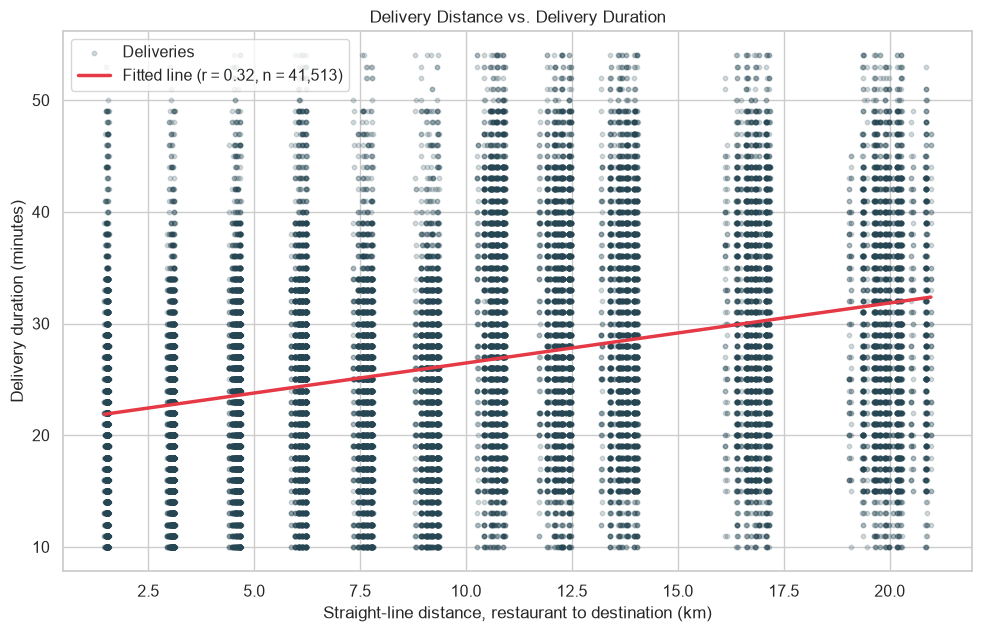

In [14]:
if HAS_DISTANCE:
    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.scatter(pair["distance_km"], pair[TARGET], s=10, alpha=0.2, color="#264653", label="Deliveries", rasterized=True)
    xs = np.linspace(pair["distance_km"].min(), pair["distance_km"].max(), 100)
    ax.plot(xs, slope * xs + intercept, color="#e63946", linewidth=2.5, label=f"Fitted line (r = {r:.2f}, n = {len(pair):,})")
    ax.set_title("Delivery Distance vs. Delivery Duration")
    ax.set_xlabel("Straight-line distance, restaurant to destination (km)")
    ax.set_ylabel("Delivery duration (minutes)")
    ax.legend(loc="upper left")
    fig.tight_layout()
    save_chart(fig, "04_distance_vs_duration.png")
    plt.show()

In [15]:
if HAS_DISTANCE:
    strength = "negligible" if abs(r) < 0.1 else "weak" if abs(r) < 0.3 else "moderate" if abs(r) < 0.5 else "strong"
    direction = "positive" if r > 0 else "negative"
    show_md("**Interpretation:** " +
        f"The relationship is {strength} and {direction} (r = {r:.2f}, n = {len(pair):,}), with the fitted line changing by {slope:+.1f} minutes for each additional kilometre. "
        f"Distance accounts for only about {r ** 2 * 100:.0f}% of the variation in duration, so most of the spread comes from other factors; {n_unusual:,} deliveries lie more than 3 residual standard deviations from the line, and {n_at_max:,} {'delivery sits' if n_at_max == 1 else 'deliveries sit'} at the maximum duration of {pair[TARGET].max()} minutes. "
        f"A limitation is that distance is straight-line and not road distance, {n_excluded_dist:,} deliveries with invalid coordinates are excluded, and overlapping points hide how densely deliveries cluster.")

**Interpretation:** The relationship is moderate and positive (r = 0.32, n = 41,513), with the fitted line changing by +0.5 minutes for each additional kilometre. Distance accounts for only about 10% of the variation in duration, so most of the spread comes from other factors; 76 deliveries lie more than 3 residual standard deviations from the line, and 82 deliveries sit at the maximum duration of 54 minutes. A limitation is that distance is straight-line and not road distance, 4,071 deliveries with invalid coordinates are excluded, and overlapping points hide how densely deliveries cluster.

## 6. Chart 5: Delivery-Duration Distribution by Vehicle Type (Box Plot)

**What:** one box per vehicle type. The line inside a box is the **median**, the box spans the **interquartile range** (middle 50%), the whiskers show the typical range, and the dots are **outliers**.
**Why:** a box plot compares the whole distribution, not just an average, so differences in spread and extremes are visible alongside the central values.

In [16]:
VEHICLE_COL = "Type_of_vehicle"
vehicle_ok = VEHICLE_COL in df.columns
if vehicle_ok:
    sub = df.dropna(subset=[VEHICLE_COL])
    vehicle_excl = len(df) - len(sub)
    rows = []
    for name, s in sub.groupby(VEHICLE_COL)[TARGET]:
        a, b = s.quantile(0.25), s.quantile(0.75)
        out = int(((s < a - 1.5 * (b - a)) | (s > b + 1.5 * (b - a))).sum())
        rows.append({"Vehicle type": name, "Deliveries": len(s), "Median (min)": s.median(), "Q1 (min)": a, "Q3 (min)": b,
                     "IQR (min)": b - a, "Outliers": out})
    v = pd.DataFrame(rows).sort_values("Median (min)").reset_index(drop=True)
    show_md("**Values used in Chart 5**", "", md_table(v.round(1)))
    print(f"Deliveries excluded (vehicle value missing): {vehicle_excl:,}")
else:
    show_md("The vehicle-type field is not available, so Chart 5 could not be created.")

**Values used in Chart 5**

| Vehicle type | Deliveries | Median (min) | Q1 (min) | Q3 (min) | IQR (min) | Outliers |
| --- | --- | --- | --- | --- | --- | --- |
| electric_scooter | 3814 | 24.0 | 17.0 | 30.0 | 13.0 | 1 |
| scooter | 15273 | 24.0 | 17.0 | 30.0 | 13.0 | 3 |
| bicycle | 68 | 26.0 | 19.0 | 32.2 | 13.2 | 0 |
| motorcycle | 26429 | 26.0 | 20.0 | 34.0 | 14.0 | 0 |

Deliveries excluded (vehicle value missing): 0


Saved: C:\Users\HP\Documents\food-delivery-data-analysis\visualizations\05_vehicle_comparison.png


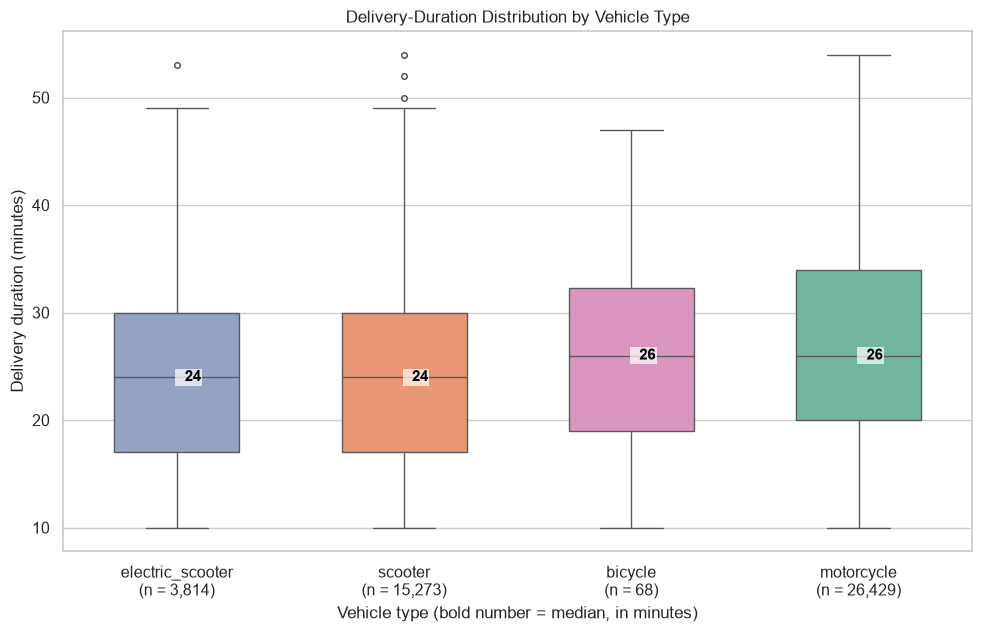

In [17]:
if vehicle_ok:
    order_v = v["Vehicle type"].tolist()
    labels = [f"{name}\n(n = {int(n):,})" for name, n in zip(v["Vehicle type"], v["Deliveries"])]
    fig, ax = plt.subplots(figsize=(10, 6.5))
    sns.boxplot(data=sub, x=VEHICLE_COL, y=TARGET, order=order_v, hue=VEHICLE_COL, palette="Set2", legend=False,
                width=0.55, flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "white", "markeredgecolor": "#444444"}, ax=ax)
    for i, med in enumerate(v["Median (min)"]):
        ax.text(i, med, f"  {med:.0f}", va="center", ha="left", fontsize=11, fontweight="bold", color="black",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))
    ax.set_xticks(range(len(order_v)))
    ax.set_xticklabels(labels)
    ax.set_title("Delivery-Duration Distribution by Vehicle Type")
    ax.set_xlabel("Vehicle type (bold number = median, in minutes)")
    ax.set_ylabel("Delivery duration (minutes)")
    fig.tight_layout()
    save_chart(fig, "05_vehicle_comparison.png")
    plt.show()

In [18]:
if vehicle_ok:
    lo, hi = v.iloc[0], v.iloc[-1]
    gap = hi["Median (min)"] - lo["Median (min)"]
    closeness = "differ only slightly" if gap <= 3 else "differ noticeably"
    with_out = int((v["Outliers"] > 0).sum())
    largest, smallest = v.sort_values("Deliveries").iloc[-1], v.sort_values("Deliveries").iloc[0]
    show_md("**Interpretation:** " +
        f"Median duration runs from {lo['Median (min)']:.0f} min (`{lo['Vehicle type']}`) to {hi['Median (min)']:.0f} min (`{hi['Vehicle type']}`), so central values {closeness}, while the interquartile ranges of {v['IQR (min)'].min():.0f} to {v['IQR (min)'].max():.0f} minutes show wide spread within every vehicle type. "
        f"Outliers appear in {with_out} of {len(v)} vehicle types ({int(v['Outliers'].sum()):,} points in total), which suggests a few unusually slow deliveries are not tied to one vehicle. "
        f"A limitation is that group sizes are very uneven ({int(largest['Deliveries']):,} for `{largest['Vehicle type']}` versus {int(smallest['Deliveries']):,} for `{smallest['Vehicle type']}`), so the smallest group is less reliable, and vehicle type may be linked to city or route type.")

**Interpretation:** Median duration runs from 24 min (`electric_scooter`) to 26 min (`motorcycle`), so central values differ only slightly, while the interquartile ranges of 13 to 14 minutes show wide spread within every vehicle type. Outliers appear in 2 of 4 vehicle types (4 points in total), which suggests a few unusually slow deliveries are not tied to one vehicle. A limitation is that group sizes are very uneven (26,429 for `motorcycle` versus 68 for `bicycle`), so the smallest group is less reliable, and vehicle type may be linked to city or route type.

## 7. Export Check

In [19]:
expected = ["01_delivery_duration_distribution.png", "02_traffic_comparison.png", "03_weather_comparison.png",
            "04_distance_vs_duration.png", "05_vehicle_comparison.png"]
rows = []
for f in expected:
    p = os.path.join(VIS_DIR, f)
    rows.append({"File": f, "Saved": os.path.exists(p), "Size (KB)": round(os.path.getsize(p) / 1024) if os.path.exists(p) else 0})
check = pd.DataFrame(rows)
show_md("**Exported charts in `visualizations/`**", "", md_table(check))
assert check["Saved"].all(), "One or more charts were not exported; check that the required fields exist"
print("All five charts exported.")

**Exported charts in `visualizations/`**

| File | Saved | Size (KB) |
| --- | --- | --- |
| 01_delivery_duration_distribution.png | True | 63 |
| 02_traffic_comparison.png | True | 62 |
| 03_weather_comparison.png | True | 88 |
| 04_distance_vs_duration.png | True | 404 |
| 05_vehicle_comparison.png | True | 64 |

All five charts exported.


## 8. Limitations and Notes

- **Associations, not causes.** Every chart shows how delivery duration differs across groups. None of them control for other factors, so differences should not be read as effects of traffic, weather, distance or vehicle.
- **Overlapping factors.** Traffic, distance, weather and vehicle type can overlap (for example, longer deliveries may be more common in heavy traffic), which the Week 2 tables checked with mean distance.
- **Distance is straight-line**, not road distance, and is only available for rows with valid coordinates.
- **Missing values** (kept as missing in Week 1) are excluded from each chart where the relevant field is missing, and the number excluded is printed under each table.
- **Chart design choices.** Bar charts start at zero so heights are comparable; the histogram uses 2-minute bins; the box plot uses the standard 1.5 x IQR rule for outliers.
- **Week 4** will turn these findings into recommendations.